# HNODE: Flow Past a Cylinder (FPAC)

This notebook trains a conditional HNODE on 2D flow past a cylinder simulated at multiple Reynolds numbers.
The state is represented as a fixed-basis PCA expansion (64 modes) computed offline from the training data.
The model is conditioned on `z = log(Re)`, allowing it to generalise across Reynolds numbers.

**Data**: Pre-computed PCA coefficients — a single `.pt` file of shape
`(n_Re, n_time_steps, n_modes)`. The raw CFD snapshots are not required.

**Checkpoint**: Set `CHECKPOINT_PATH` to a `.pt` file to resume from a saved checkpoint,
or set it to `None` to train from scratch.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from pca_datasets import PCADataset, create_dataloader
from hybrid_node_solver import HybridNODESolver
from neural_networks import CrossAttnTransformer
from soap import SOAP

torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
print(f"Using device: {device}")

Using device: cuda


## Configuration

In [2]:
# Path to the PCA cache file.
# This is a .pt file containing keys:
#   'data_coefficients' : tensor of shape (n_Re * n_time_steps, n_modes)
#   'basis_functions'   : tensor of shape (n_modes, n_spatial_dofs)
#   'S'                 : singular values, shape (n_modes,)
DATA_PATH = "./repro.pt"

# Path to a saved checkpoint to resume training, or None to train from scratch.
CHECKPOINT_PATH = "cond_fpac_prod_v4.pth"
SAVE_PATH = "fpac_checkpoint.pt"
SAVE_EVERY = 500

## Dataset

The PCA cache file contains the pre-computed coefficients, basis functions, and singular
values from the offline SVD. Passing it via `cache_path=` lets `PCADataset` skip the SVD
entirely — no raw CFD snapshots are needed. The basis functions are retained so model
outputs can be projected back to physical space for visualisation.

In [3]:
num_basis_functions = 64  # PCA modes (state dimension)
data_dt = 0.1  # time step in the dataset
num_time_steps_per_data_sample = 32
N = 8  # number of training rollouts
batch_size = 64

data_delta_t = data_dt * num_time_steps_per_data_sample / N
N_t = (
    num_time_steps_per_data_sample // N
) + 1  # collocation points per rollout (M = N_t - 1)

# Reynolds numbers in the dataset — must match the trajectory order in DATA_PATH
re_values = [60, 80, 100, 150, 200, 300, 400, 600, 800]
z_data = torch.tensor(re_values, dtype=torch.float64).unsqueeze(-1).log()
z_mean = z_data.mean(dim=0, keepdim=True)
z_std = z_data.std(dim=0, keepdim=True)
z_data = (z_data - z_mean) / z_std

fpac_dataset = PCADataset(
    raw_data=None,
    z_data=z_data,
    dt=data_dt,
    num_basis_functions=num_basis_functions,
    num_time_steps_per_sample=num_time_steps_per_data_sample,
    cache_path=DATA_PATH,
    device=device,
)
data_delta_t = (data_delta_t / fpac_dataset.t_scale).item()
dataloader = create_dataloader(fpac_dataset, batch_size=batch_size)
print(
    f"Dataset ready. t_scale={fpac_dataset.t_scale:.4f}, scaled delta_t={data_delta_t:.6f}"
)
print(f"Effective dataset length: {len(fpac_dataset)} samples")
print(
    f"Basis functions shape: {fpac_dataset.basis_functions.shape}"
)  # (n_modes, n_spatial_dofs)

Dataset ready. t_scale=0.9770, scaled delta_t=0.409421
Effective dataset length: 53712 samples
Basis functions shape: torch.Size([64, 143739])


## Model

In [4]:
nn_rhs_model = CrossAttnTransformer(
    problem_dim=num_basis_functions,
    latent_dim=64 * 4,
    num_blocks=3,
    num_heads=4,
    z_dim=z_data.shape[1],
    dropout_rate=0,
    activation=torch.nn.Tanh(),
    use_self_attention_z_block=True,
).to(device)

solver = HybridNODESolver(
    nn_rhs_model,
    data_delta_t,
    N_t,
    num_basis_functions,
    N,
    backprop_type="matrix_free",
    use_manual_jacobian=True,
    use_sparse_solver=False,
    use_cpu_solver=False,
    verbose=False,
    device=device,
)

n_params = sum(p.numel() for p in nn_rhs_model.parameters())
print(f"Model parameters: {n_params:,}")

Model parameters: 3,205,704


/home/kinch/PIMI-Lab/neural_odes/hnode_code/hybrid_node_solver.py:286: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:53.)
  M_p0 = p0_eval @ p0_eval.T


## Optimizer and Checkpoint

In [7]:
def get_param_groups(model, weight_decay=1e-4):
    """Separate transformer params into decay / no-decay groups (standard practice)."""
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim <= 1 or "bias" in name or "norm" in name.lower() or "ln" in name:
            no_decay.append(param)
        else:
            decay.append(param)
    return [
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ]


optimizer = SOAP(
    get_param_groups(nn_rhs_model),
    precondition_frequency=10,
    lr=1e-3,
)

loss_history = []

if CHECKPOINT_PATH is not None:
    import os

    if os.path.exists(CHECKPOINT_PATH):
        checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
        # Handle both key conventions that appear across saves
        state_dict_key = (
            "model_state_dict" if "model_state_dict" in checkpoint else "nn_rhs_model"
        )
        nn_rhs_model.load_state_dict(checkpoint[state_dict_key])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        loss_history = checkpoint.get("loss_history", [])
        print(
            f"Loaded checkpoint from {CHECKPOINT_PATH} ({len(loss_history)} steps so far)"
        )
    else:
        print(f"Checkpoint not found at {CHECKPOINT_PATH}, training from scratch.")

Loaded checkpoint from cond_fpac_prod_v4.pth (4700 steps so far)


## Training

In [8]:
def save_checkpoint():
    import os

    torch.save(
        {
            "nn_rhs_model": nn_rhs_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "loss_history": loss_history,
        },
        SAVE_PATH,
    )


NUM_EPOCHS = 0

for epoch in range(NUM_EPOCHS):
    for batch_ndx, batch in enumerate(dataloader):
        _, u_hat_rollout = solver.evolve_batch(batch)
        loss = torch.nn.functional.mse_loss(u_hat_rollout, batch["u_hat"])

        optimizer.zero_grad()
        with torch.autograd.detect_anomaly():
            loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        print(
            f"Epoch {epoch} | Batch {batch_ndx}/{len(dataloader)} | Loss {loss.item():.6e}"
        )

        if len(loss_history) % SAVE_EVERY == 0:
            save_checkpoint()

## Evaluation: Training Loss

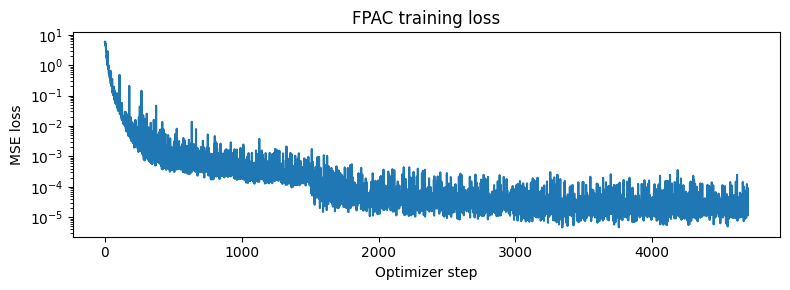

In [9]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.semilogy(loss_history)
ax.set_xlabel("Optimizer step")
ax.set_ylabel("MSE loss")
ax.set_title("FPAC training loss")
plt.tight_layout()
plt.show()

## Evaluation: PCA Mode Trajectories

Roll out the model for each Reynolds number in the dataset and compare the predicted
PCA coefficient trajectories against the ground truth.

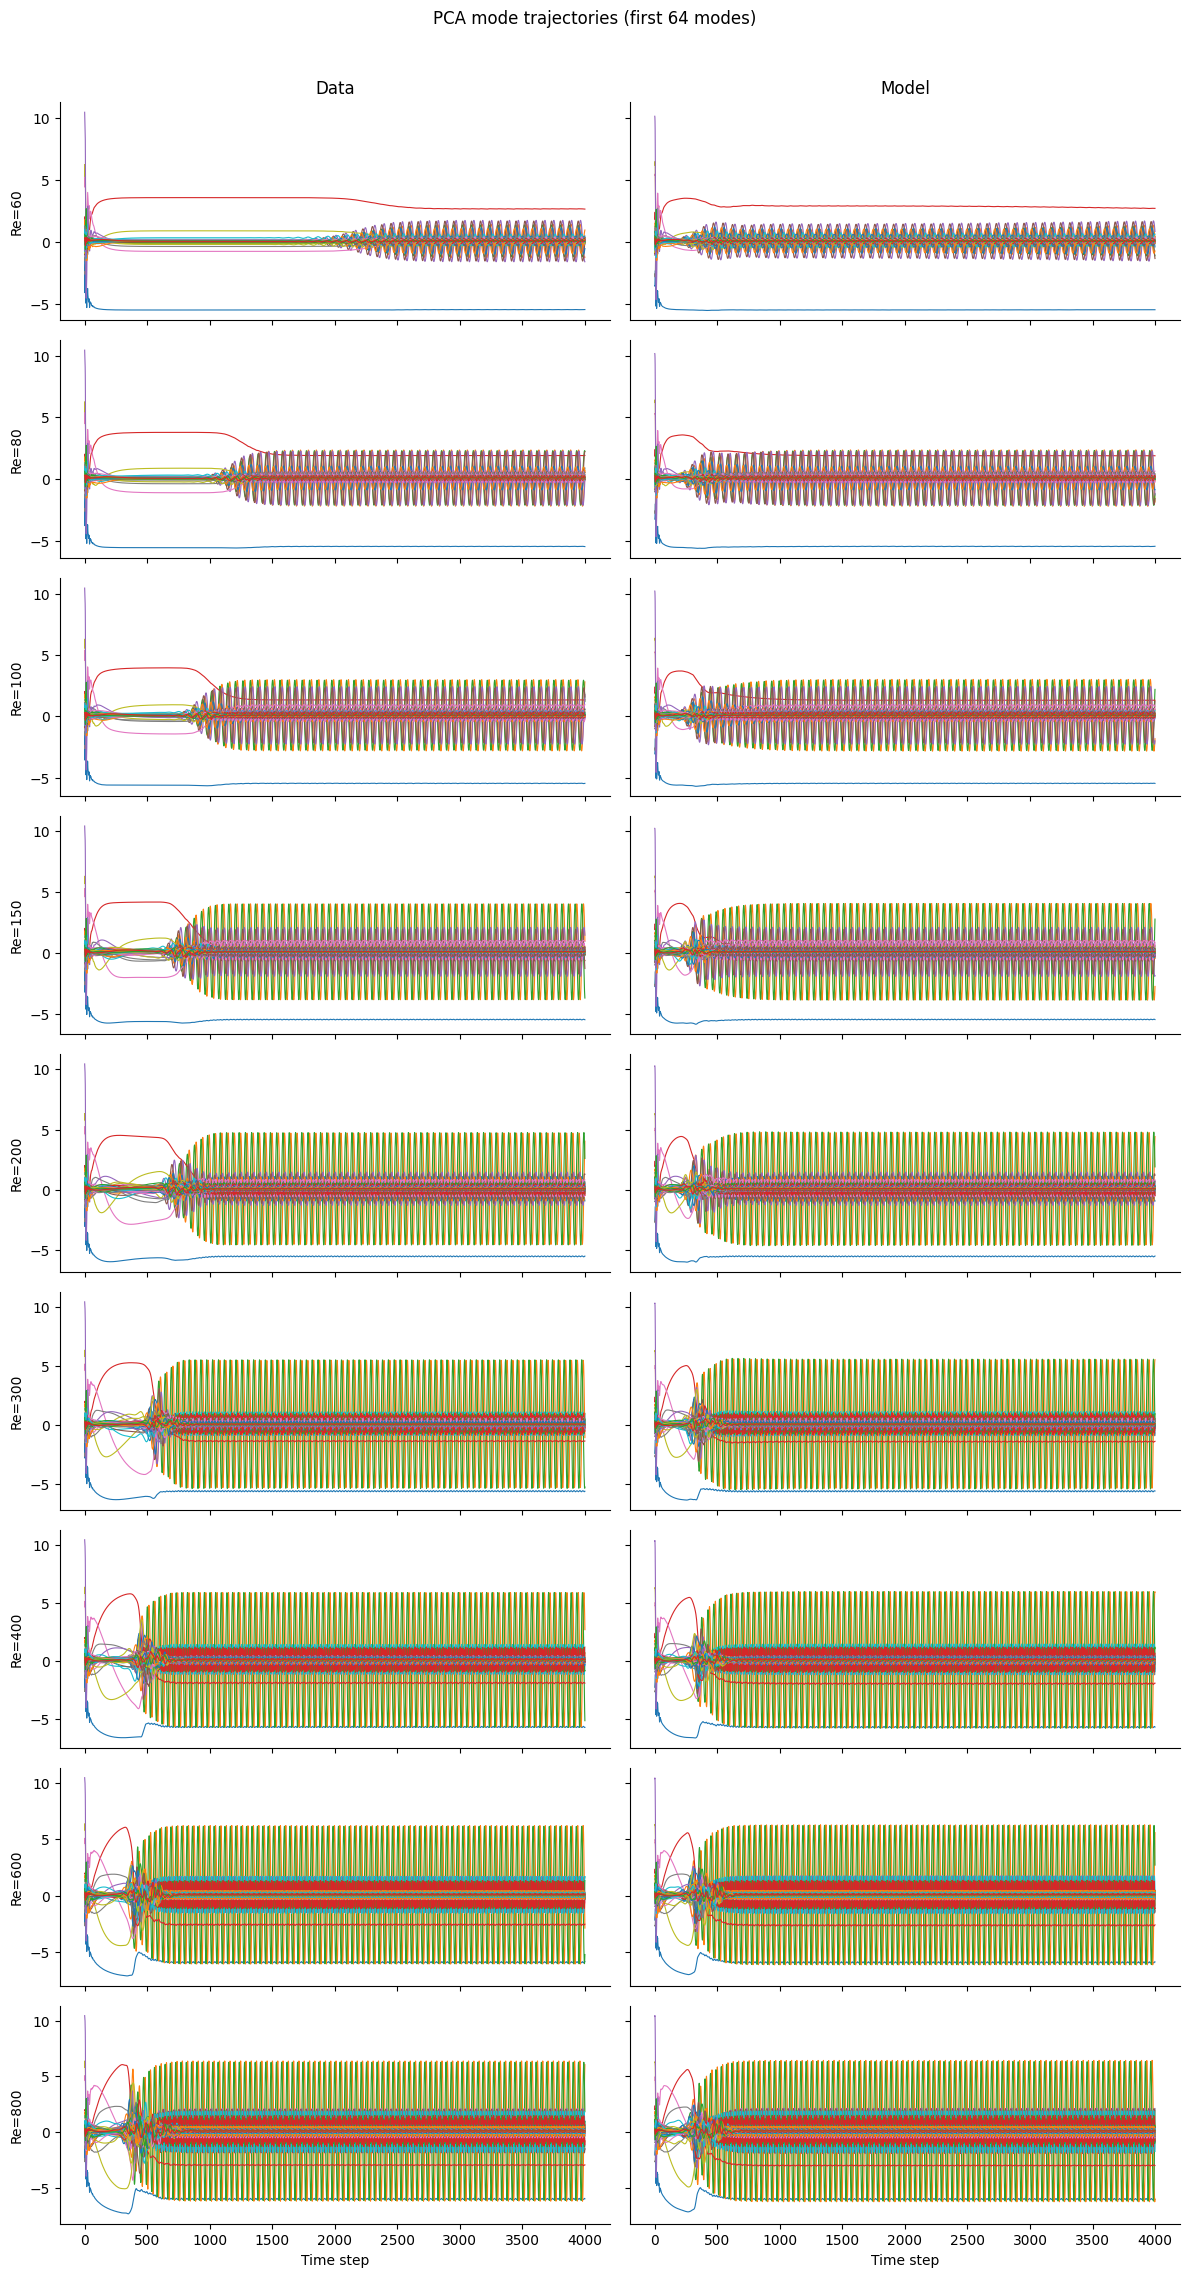

In [14]:
nn_rhs_model.eval()

n_modes_to_plot = 64
n_Re = len(re_values)

fig, axes = plt.subplots(n_Re, 2, figsize=(12, 2.5 * n_Re), sharex=True, sharey="row")

for z_ndx, re in enumerate(re_values):
    sample = fpac_dataset.get_item_by_ndx(z_ndx, t_ndx=0)
    batch = {
        k: v.unsqueeze(0).to(device)
        for k, v in sample.items()
        if isinstance(v, torch.Tensor)
    }

    with torch.no_grad():
        _, u_hat_rollout = solver.rollout_batch(batch, num_rollouts=1000)

    pred = u_hat_rollout[0].cpu().numpy()  # (T, n_modes)
    true = fpac_dataset.u_hats[z_ndx].cpu().numpy()  # (T, n_modes)
    T = pred.shape[0]

    ax_data, ax_model = axes[z_ndx, 0], axes[z_ndx, 1]
    for i in range(n_modes_to_plot):
        ax_data.plot(true[:T, i], lw=0.8, label=f"Mode {i+1}")
        ax_model.plot(pred[:, i], lw=0.8, label=f"Mode {i+1}")

    ax_data.set_ylabel(f"Re={re}")
    for ax in (ax_data, ax_model):
        ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].set_title("Data")
axes[0, 1].set_title("Model")
# axes[0, 1].legend(fontsize=7, loc="upper right", frameon=False)
axes[-1, 0].set_xlabel("Time step")
axes[-1, 1].set_xlabel("Time step")
plt.suptitle(f"PCA mode trajectories (first {n_modes_to_plot} modes)", y=1.01)
plt.tight_layout()
plt.show()